In [22]:
import sys

print(sys.executable)

d:\Bosscode_ML_\dataset\reactor_CFD_ML_Dataset\.venv\Scripts\python.exe


# Stirred Reactor CFD Surrogate Model

## 1. Problem Statement

The objective of this project is to develop a machine learning
surrogate model that predicts CFD-derived hydrodynamic properties
of a stirred reactor from its design and operating parameters.

The input features describe the reactor geometry, impeller
configuration, internal components, and operating conditions.

The target variables are:

- strainRate_p50
- epsilon_p50
- k_p50
- Umag_p50

This is formulated as a supervised multi-output regression problem.

In [23]:
import sys

!{sys.executable} -m pip install pandas

In [15]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 2.3.3


In [16]:
import numpy as np

print("NumPy version:", np.__version__)

NumPy version: 2.2.6


In [17]:
df=pd.read_csv("training_data_set.csv")
print("dataset shape:", df.shape)

dataset shape: (768, 24)


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
print("dataset:",df.shape)

dataset: (768, 24)


In [29]:
df.nunique()

volume                  36
reactor_diameter        12
liquid_height           36
bottom_depth            12
n_impeller               2
diameter_impeller_1     12
ax_pos_impeller_1       12
n_blades_1               1
pitch_angle_1            1
diameter_impeller_2     13
ax_pos_impeller_2       13
n_blades_2               4
pitch_angle_2            3
diameter_impeller_3      1
ax_pos_impeller_3        1
n_blades_3               1
pitch_angle_3            1
n_diptubes               1
n_baffles                1
rpm                     46
strainRate_p50         767
epsilon_p50            767
k_p50                  767
Umag_p50               767
dtype: int64

In [30]:
print(df.shape)
print(df.columns.tolist())
df.head()

(768, 24)
['volume', 'reactor_diameter', 'liquid_height', 'bottom_depth', 'n_impeller', 'diameter_impeller_1', 'ax_pos_impeller_1', 'n_blades_1', 'pitch_angle_1', 'diameter_impeller_2', 'ax_pos_impeller_2', 'n_blades_2', 'pitch_angle_2', 'diameter_impeller_3', 'ax_pos_impeller_3', 'n_blades_3', 'pitch_angle_3', 'n_diptubes', 'n_baffles', 'rpm', 'strainRate_p50', 'epsilon_p50', 'k_p50', 'Umag_p50']


,volume,reactor_diameter,liquid_height,bottom_depth,n_impeller,diameter_impeller_1,ax_pos_impeller_1,n_blades_1,pitch_angle_1,diameter_impeller_2,...,ax_pos_impeller_3,n_blades_3,pitch_angle_3,n_diptubes,n_baffles,rpm,strainRate_p50,epsilon_p50,k_p50,Umag_p50
0,0.223838,0.1,0.015167,0.02,1,0.035,-0.014,2,0,0.00,...,0,0,0,0,4,1000,35.991812,0.040620,0.004243,0.219517
1,0.537212,0.1,0.055067,0.02,2,0.035,-0.014,2,0,0.05,...,0,0,0,0,4,1000,50.097474,0.473682,0.031069,0.352871
2,0.805819,0.1,0.089267,0.02,2,0.035,-0.014,2,0,0.05,...,0,0,0,0,4,1000,40.765123,0.469849,0.033162,0.299601
3,0.223838,0.1,0.015167,0.02,1,0.035,-0.014,2,0,0.00,...,0,0,0,0,4,250,7.227823,0.000414,0.000177,0.048872
4,0.223838,0.1,0.015167,0.02,1,0.035,-0.014,2,0,0.00,...,0,0,0,0,4,500,16.879798,0.005030,0.001135,0.105326


In [31]:
for i , col in enumerate(df.columns):
    print(i,":", col)

0 : volume
1 : reactor_diameter
2 : liquid_height
3 : bottom_depth
4 : n_impeller
5 : diameter_impeller_1
6 : ax_pos_impeller_1
7 : n_blades_1
8 : pitch_angle_1
9 : diameter_impeller_2
10 : ax_pos_impeller_2
11 : n_blades_2
12 : pitch_angle_2
13 : diameter_impeller_3
14 : ax_pos_impeller_3
15 : n_blades_3
16 : pitch_angle_3
17 : n_diptubes
18 : n_baffles
19 : rpm
20 : strainRate_p50
21 : epsilon_p50
22 : k_p50
23 : Umag_p50


## 2. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the
structure, quality, distribution, and relationships within the dataset.

The objectives of this EDA are to:

- Understand the structure of the dataset
- Examine the data types
- Identify missing values
- Identify duplicate observations
- Understand the range and distribution of the variables
- Examine the distributions of the target variables
- Investigate relationships between features and targets
- Identify potential outliers
- Examine correlations between variables

In [32]:
print("number of rows", df.shape[0])
print("number of columns", df.shape[1])

number of rows 768
number of columns 24


### 2.1 Data Types

We examine the data type of each variable to determine whether
the variables are numerical or categorical and whether any
conversion or preprocessing may be required.

In [33]:
df.dtypes

volume                 float64
reactor_diameter       float64
liquid_height          float64
bottom_depth           float64
n_impeller               int64
diameter_impeller_1    float64
ax_pos_impeller_1      float64
n_blades_1               int64
pitch_angle_1            int64
diameter_impeller_2    float64
ax_pos_impeller_2      float64
n_blades_2               int64
pitch_angle_2            int64
diameter_impeller_3      int64
ax_pos_impeller_3        int64
n_blades_3               int64
pitch_angle_3            int64
n_diptubes               int64
n_baffles                int64
rpm                      int64
strainRate_p50         float64
epsilon_p50            float64
k_p50                  float64
Umag_p50               float64
dtype: object

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   volume               768 non-null    float64
 1   reactor_diameter     768 non-null    float64
 2   liquid_height        768 non-null    float64
 3   bottom_depth         768 non-null    float64
 4   n_impeller           768 non-null    int64  
 5   diameter_impeller_1  768 non-null    float64
 6   ax_pos_impeller_1    768 non-null    float64
 7   n_blades_1           768 non-null    int64  
 8   pitch_angle_1        768 non-null    int64  
 9   diameter_impeller_2  768 non-null    float64
 10  ax_pos_impeller_2    768 non-null    float64
 11  n_blades_2           768 non-null    int64  
 12  pitch_angle_2        768 non-null    int64  
 13  diameter_impeller_3  768 non-null    int64  
 14  ax_pos_impeller_3    768 non-null    int64  
 15  n_blades_3           768 non-null    int

### 2.2 Missing Values

We check for missing values because many machine learning
algorithms cannot directly handle missing data, and missing
values may require imputation or removal.

In [39]:
missing_values=df.isnull().sum()
display(missing_values)

volume                 0
reactor_diameter       0
liquid_height          0
bottom_depth           0
n_impeller             0
diameter_impeller_1    0
ax_pos_impeller_1      0
n_blades_1             0
pitch_angle_1          0
diameter_impeller_2    0
ax_pos_impeller_2      0
n_blades_2             0
pitch_angle_2          0
diameter_impeller_3    0
ax_pos_impeller_3      0
n_blades_3             0
pitch_angle_3          0
n_diptubes             0
n_baffles              0
rpm                    0
strainRate_p50         0
epsilon_p50            0
k_p50                  0
Umag_p50               0
dtype: int64

### 2.3 Duplicate Observations

We check whether the dataset contains completely duplicated rows.
Duplicate observations can affect model training and should be
investigated before deciding whether they should be removed.

In [41]:
duplicount=df.duplicated().sum()
print("number of duplicated rows:",duplicount)

number of duplicated rows: 1


### 2.4 Descriptive Statistics

Descriptive statistics are used to understand the central tendency,
spread, and range of the numerical variables.

In [43]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
volume,768.0,795.73,1543.26,0.22,4.30,34.38,805.82,6446.55
reactor_diameter,768.0,0.73,0.64,0.10,0.20,0.40,1.08,2.00
liquid_height,768.0,0.39,0.45,0.02,0.08,0.20,0.55,1.79
bottom_depth,768.0,0.15,0.13,0.02,0.04,0.08,0.22,0.40
n_impeller,768.0,1.67,0.47,1.00,1.00,2.00,2.00,2.00
diameter_impeller_1,768.0,0.26,0.22,0.04,0.07,0.14,0.38,0.70
ax_pos_impeller_1,768.0,-0.10,0.09,-0.28,-0.15,-0.06,-0.03,-0.01
n_blades_1,768.0,2.00,0.00,2.00,2.00,2.00,2.00,2.00
pitch_angle_1,768.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
diameter_impeller_2,768.0,0.24,0.31,0.00,0.00,0.10,0.38,1.00


### 2.5 counting the number of uniques values for each features

In [44]:
unique_counts = df.nunique().sort_values()

display(unique_counts)

n_blades_1               1
ax_pos_impeller_3        1
n_blades_3               1
pitch_angle_1            1
diameter_impeller_3      1
n_baffles                1
n_diptubes               1
pitch_angle_3            1
n_impeller               2
pitch_angle_2            3
n_blades_2               4
bottom_depth            12
ax_pos_impeller_1       12
reactor_diameter        12
diameter_impeller_1     12
ax_pos_impeller_2       13
diameter_impeller_2     13
volume                  36
liquid_height           36
rpm                     46
strainRate_p50         767
epsilon_p50            767
k_p50                  767
Umag_p50               767
dtype: int64

investigating the duplicated row. [df.duplicated(keep=False)]  this partgenerates  a series of true or false values matching the length of the dataset.

 The Inside: df.duplicated(keep=False)
 This part generates a Series of True and False values matching the length of your dataset.It checks every single row.If a row is a duplicate, it marks it True.
 
 Because keep=False is used, it marks all occurrences of the duplicates as True (both the original row and its copies).If you printed just this inner part, you would get a long list of True and False indicators, not your actual data.2. The Outside: df[...]The outer df[...] acts like a filter bracket.It looks at the True/False list you generated inside.It throws away every row marked False.It keeps and displays only the rows marked True.


In [6]:
df[df.duplicated(keep=False)]

,volume,reactor_diameter,liquid_height,bottom_depth,n_impeller,diameter_impeller_1,ax_pos_impeller_1,n_blades_1,pitch_angle_1,diameter_impeller_2,...,ax_pos_impeller_3,n_blades_3,pitch_angle_3,n_diptubes,n_baffles,rpm,strainRate_p50,epsilon_p50,k_p50,Umag_p50
374,51.572385,0.4,0.357067,0.08,2,0.14,-0.056,2,0,0.2,...,0,0,0,0,4,396,10.509822,0.115548,0.034727,0.333317
386,51.572385,0.4,0.357067,0.08,2,0.14,-0.056,2,0,0.2,...,0,0,0,0,4,396,10.509822,0.115548,0.034727,0.333317


In [18]:
df=df.drop_duplicates()

In [19]:
print("dataset shape:",df.shape)
print("Number of duplicated rows:",df.duplicated().sum())

dataset shape: (767, 24)
Number of duplicated rows: 0


EDA - Exploratory Data Analysis

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
volume,767.0,796.703223,1544.032371,0.223838,4.297699,34.381590,805.818516,6446.548125
reactor_diameter,767.0,0.734029,0.640769,0.100000,0.200000,0.400000,1.150000,2.000000
liquid_height,767.0,0.390070,0.450817,0.015167,0.082600,0.197167,0.550667,1.785333
bottom_depth,767.0,0.146806,0.128154,0.020000,0.040000,0.080000,0.230000,0.400000
n_impeller,767.0,1.666232,0.471866,1.000000,1.000000,2.000000,2.000000,2.000000
diameter_impeller_1,767.0,0.256910,0.224269,0.035000,0.070000,0.140000,0.402500,0.700000
ax_pos_impeller_1,767.0,-0.102764,0.089708,-0.280000,-0.161000,-0.056000,-0.028000,-0.014000
n_blades_1,767.0,2.000000,0.000000,2.000000,2.000000,2.000000,2.000000,2.000000
pitch_angle_1,767.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
diameter_impeller_2,767.0,0.244589,0.313733,0.000000,0.000000,0.100000,0.380000,1.000000


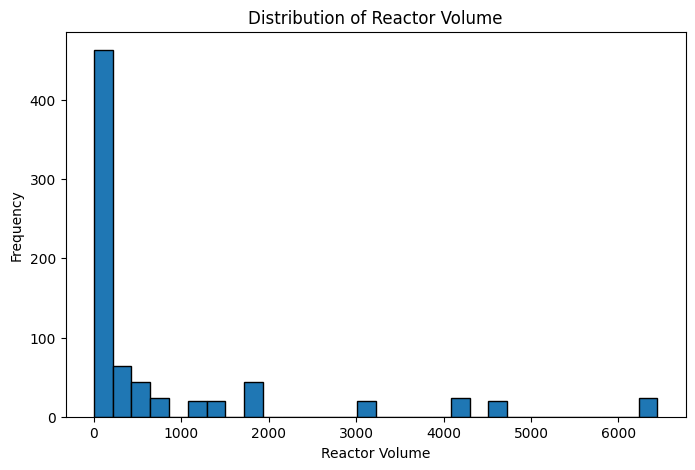

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(df['volume'], bins=30, edgecolor="black")

plt.xlabel("Reactor Volume")
plt.ylabel("Frequency")
plt.title("Distribution of Reactor Volume")

plt.show()

from the above, it can be seen that 
1. The data is right skewed
2. distribution is uneven
3. Can have extreme values

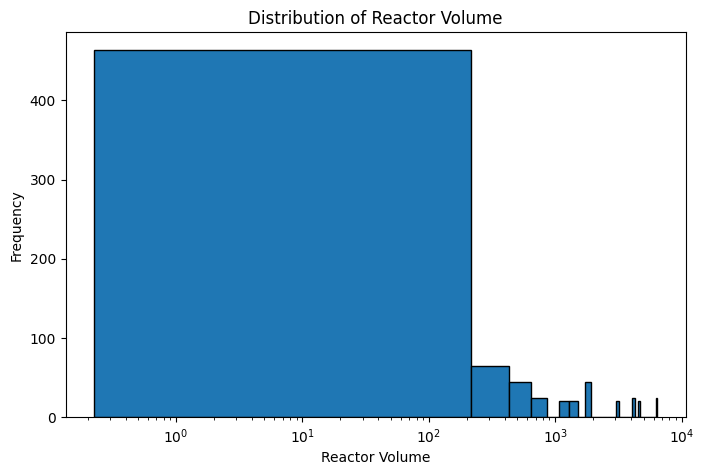

In [22]:
plt.figure(figsize=(8,5))

plt.hist(df['volume'], bins=30, edgecolor="black")

plt.xscale("log")
plt.xlabel("Reactor Volume")
plt.ylabel("Frequency")
plt.title("Distribution of Reactor Volume")

plt.show()

1. right skewness is present
2. spans several orders magnitude
3. large reators are legitimately sparse.

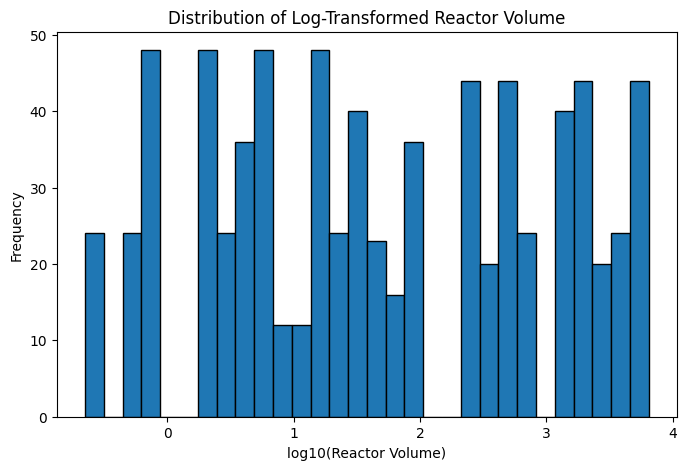

In [23]:
log_volume = np.log10(df["volume"])

plt.figure(figsize=(8, 5))
plt.hist(log_volume, bins=30, edgecolor="black")

plt.xlabel("log10(Reactor Volume)")
plt.ylabel("Frequency")
plt.title("Distribution of Log-Transformed Reactor Volume")

plt.show()